# Shared Image Loader

## What this notebook is for

I made this notebook so anyone on the team can load the **same EMNIST dataset** without redoing preprocessing or creating new splits.

This notebook is **not** a preprocessing notebook. It only loads the files that were already prepared.

It works for:
- **Google Colab**
- **Local Jupyter / VS Code**
- **Kaggle**

### Important
- Use the provided **train / val / test** files exactly as they are.
- The `.npz` files are **already normalized to 0–1**, so **do not divide by 255 again**.
- If you are using this notebook in a different environment, the only part you usually need to change is the **dataset path / setup cell**.


## Cell 1 — Choose where you are running this notebook

This is the **main setup cell**.

If you are using:
- **Google Colab** → set `ENVIRONMENT = "colab"`
- **VS Code / local Jupyter** → set `ENVIRONMENT = "local"`
- **Kaggle** → set `ENVIRONMENT = "kaggle"`
- If you want the notebook to try detecting automatically, leave it as `"auto"`.

If the dataset is not in the default location, use `DATA_DIR_OVERRIDE`.


In [1]:
from pathlib import Path

# Change this only if needed.
# Options: "auto", "colab", "local", "kaggle"
ENVIRONMENT = "auto"

# If you already know the exact folder path, put it here.
# Otherwise leave it as an empty string and the notebook will try the defaults.
DATA_DIR_OVERRIDE = ""

print("Environment setting:", ENVIRONMENT)
print("DATA_DIR_OVERRIDE:", DATA_DIR_OVERRIDE if DATA_DIR_OVERRIDE else "<not set>")


Environment setting: auto
DATA_DIR_OVERRIDE: <not set>


## Cell 2 — Resolve the dataset location

This cell figures out where the dataset lives.

### Default locations used in this notebook
- **Colab:** `/content/drive/MyDrive/CLEANED IMAGES AND REPRESENTATIONS`
- **Local:** a folder called `CLEANED IMAGES AND REPRESENTATIONS` in the current working directory
- **Kaggle:** inside `/kaggle/input/`

If you used `DATA_DIR_OVERRIDE`, that path is used first.


In [3]:
import os
import sys


def detect_environment():
    # I kept this simple on purpose.
    # If I know where I am running, I can force it with ENVIRONMENT in Cell 1.
    if ENVIRONMENT != "auto":
        return ENVIRONMENT.lower()

    # Colab usually has google.colab available.
    try:
        import google.colab  # noqa: F401
        return "colab"
    except Exception:
        pass

    # Kaggle usually exposes this path.
    if Path("/kaggle/input").exists():
        return "kaggle"

    # If neither Colab nor Kaggle is detected, I treat it as local.
    return "local"


def find_kaggle_dataset_folder():
    # This helps if someone adds the dataset as a Kaggle input.
    base = Path("/kaggle/input")
    if not base.exists():
        return None

    # I search a few levels to find the folder containing the NPZ files.
    for path in [base] + [p for p in base.rglob("*") if p.is_dir()]:
        required = [path / "train.npz", path / "val.npz", path / "test.npz"]
        if all(p.is_file() for p in required):
            return path
    return None


runtime = detect_environment()
print("Detected environment:", runtime)

if DATA_DIR_OVERRIDE:
    DATA_DIR = Path(DATA_DIR_OVERRIDE)

elif runtime == "colab":
    from google.colab import drive

    # I mount Drive only in Colab.
    drive.mount("/content/drive")
    DATA_DIR = Path("/content/drive/MyDrive/CLEANED IMAGES AND REPRESENTATIONS")

elif runtime == "kaggle":
    found = find_kaggle_dataset_folder()
    if found is None:
        raise FileNotFoundError(
            "I could not find train.npz, val.npz, and test.npz inside /kaggle/input. "
            "Please attach the dataset first or use DATA_DIR_OVERRIDE."
        )
    DATA_DIR = found

else:
    # Local / VS Code / Jupyter Notebook
    DATA_DIR = Path("CLEANED IMAGES AND REPRESENTATIONS")

print("\nDataset folder set to:")
print(DATA_DIR)


Detected environment: colab
Mounted at /content/drive

Dataset folder set to:
/content/drive/MyDrive/CLEANED IMAGES AND REPRESENTATIONS


## Cell 3 — Check that the required files exist

This cell makes sure the three main NPZ files are there before moving forward.

If this cell fails, the most likely issue is the dataset path.


In [5]:
required_files = [
    DATA_DIR / "train.npz",
    DATA_DIR / "val.npz",
    DATA_DIR / "test.npz",
]

missing = [p for p in required_files if not p.is_file()]

print("Checking required files...
")
for path in required_files:
    if path.is_file():
        print("FOUND   ->", path.name)
    else:
        print("MISSING ->", path.name)

if missing:
    print("
I could not find all required files.")
    print("The folder I checked was:")
    print(DATA_DIR)

    if DATA_DIR.exists() and DATA_DIR.is_dir():
        print("
Files currently inside that folder:")
        for item in sorted(DATA_DIR.iterdir()):
            print(" -", item.name)

    raise FileNotFoundError(
        "Cannot find required dataset files. Update DATA_DIR / DATA_DIR_OVERRIDE so it points to the folder containing train.npz, val.npz, and test.npz."
    )

print("
Success: all required NPZ files are available.")


Checking required files...

FOUND   -> train.npz
FOUND   -> val.npz
FOUND   -> test.npz

Success: all required NPZ files are available.


## Cell 4 — Load the dataset

This loads the already preprocessed `.npz` files.

Each file contains:
- `X` → image arrays
- `y` → integer labels
- `sample_id` → sample identifiers (if included)

Again, the NPZ images are **already normalized**, so I am **not** dividing by 255 here.


In [6]:
import numpy as np


def load_split(split_name):
    path = DATA_DIR / f"{split_name}.npz"

    with np.load(path, allow_pickle=False) as data:
        X = data["X"].astype(np.float32)
        y = data["y"].astype(np.int64)
        sample_id = data["sample_id"] if "sample_id" in data.files else None

    return X, y, sample_id


X_train, y_train, id_train = load_split("train")
X_val, y_val, id_val = load_split("val")
X_test, y_test, id_test = load_split("test")

CLASS_NAMES = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

print("Loaded dataset shapes:")
print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape, y_val.shape)
print("Test: ", X_test.shape, y_test.shape)


Loaded dataset shapes:
Train: (6837, 28, 28, 1) (6837,)
Val:   (855, 28, 28, 1) (855,)
Test:  (855, 28, 28, 1) (855,)


## Cell 5 — Quick sanity checks

This cell checks shapes, pixel ranges, and class labels. It is just a safety check before anyone starts training a model.


In [7]:
def check_split(X, y, split_name):
    assert X.ndim == 4, f"{split_name}: expected 4D array, got {X.ndim}D"
    assert X.shape[1:] == (28, 28, 1), f"{split_name}: expected shape (*, 28, 28, 1), got {X.shape}"
    assert y.ndim == 1, f"{split_name}: labels should be 1D"
    assert len(X) == len(y), f"{split_name}: image/label count mismatch"
    assert np.isfinite(X).all(), f"{split_name}: found non-finite values"
    assert X.min() >= 0 and X.max() <= 1, f"{split_name}: pixel values should already be in [0, 1]"
    assert set(np.unique(y)).issubset(set(range(26))), f"{split_name}: labels must be in 0-25"


check_split(X_train, y_train, "train")
check_split(X_val, y_val, "val")
check_split(X_test, y_test, "test")

print("All sanity checks passed.")
print("Pixel range train:", float(X_train.min()), "to", float(X_train.max()))


All sanity checks passed.
Pixel range train: 0.0 to 1.0


## Cell 6 — Look at a few example images

This is optional, but it helps to quickly confirm that the images and labels match what we expect.


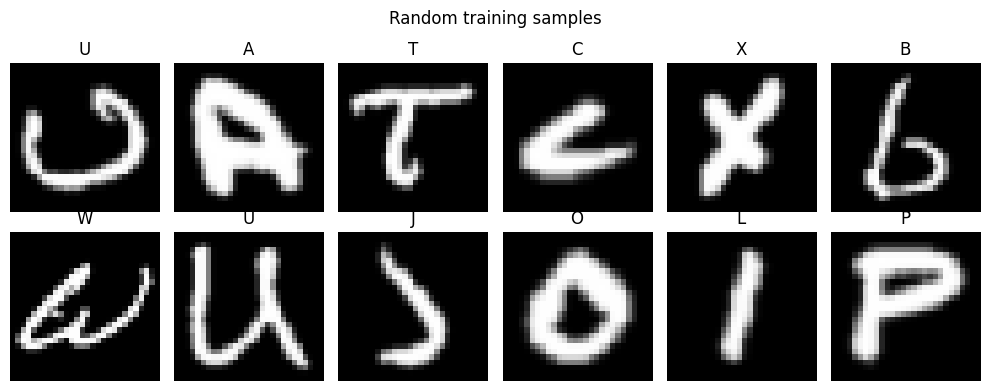

In [8]:
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
fig, axes = plt.subplots(2, 6, figsize=(10, 4))
axes = axes.ravel()

chosen = rng.choice(len(X_train), size=12, replace=False)

for ax, idx in zip(axes, chosen):
    ax.imshow(X_train[idx].squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(CLASS_NAMES[int(y_train[idx])])
    ax.axis("off")

plt.suptitle("Random training samples")
plt.tight_layout()
plt.show()


## Cell 7 — Prepare the data for an ANN baseline

A fully connected ANN usually expects each image as a flat vector.

So here I reshape each `28 × 28 × 1` image into **784 features**.


In [9]:
# ANN version: flatten each image into 784 features
X_train_ann = X_train.reshape(len(X_train), -1)
X_val_ann = X_val.reshape(len(X_val), -1)
X_test_ann = X_test.reshape(len(X_test), -1)

print("ANN-ready shapes:")
print("Train:", X_train_ann.shape)
print("Val:  ", X_val_ann.shape)
print("Test: ", X_test_ann.shape)


ANN-ready shapes:
Train: (6837, 784)
Val:   (855, 784)
Test:  (855, 784)


## Cell 8 — Prepare the data for CNNs

For CNNs, I keep the image structure as `28 × 28 × 1`.

That format works directly for TensorFlow / Keras.


In [10]:
# CNN version for TensorFlow / Keras
X_train_cnn = X_train
X_val_cnn = X_val
X_test_cnn = X_test

print("CNN-ready shapes (TensorFlow format):")
print("Train:", X_train_cnn.shape)
print("Val:  ", X_val_cnn.shape)
print("Test: ", X_test_cnn.shape)


CNN-ready shapes (TensorFlow format):
Train: (6837, 28, 28, 1)
Val:   (855, 28, 28, 1)
Test:  (855, 28, 28, 1)


## Cell 9 — Optional: prepare the data for PyTorch CNNs

PyTorch usually expects channel-first format: `(N, C, H, W)`.

So I move the last axis to the second position.


In [11]:
# Optional PyTorch format: (N, 1, 28, 28)
X_train_torch = np.transpose(X_train, (0, 3, 1, 2))
X_val_torch = np.transpose(X_val, (0, 3, 1, 2))
X_test_torch = np.transpose(X_test, (0, 3, 1, 2))

print("PyTorch CNN-ready shapes:")
print("Train:", X_train_torch.shape)
print("Val:  ", X_val_torch.shape)
print("Test: ", X_test_torch.shape)


PyTorch CNN-ready shapes:
Train: (6837, 1, 28, 28)
Val:   (855, 1, 28, 28)
Test:  (855, 1, 28, 28)


## Cell 10 — Optional: TensorFlow dataset objects

If you are using TensorFlow / Keras, this cell creates batched datasets.

You do **not** have to use this cell if you prefer working directly with NumPy arrays.


In [13]:
# This cell is optional.
# If TensorFlow is not installed in your environment, just skip it.

try:
    import tensorflow as tf

    BATCH_SIZE = 32

    train_ds = tf.data.Dataset.from_tensor_slices((X_train_cnn, y_train)).shuffle(len(X_train_cnn), seed=42).batch(BATCH_SIZE)
    val_ds = tf.data.Dataset.from_tensor_slices((X_val_cnn, y_val)).batch(BATCH_SIZE)
    test_ds = tf.data.Dataset.from_tensor_slices((X_test_cnn, y_test)).batch(BATCH_SIZE)

    print("TensorFlow datasets created successfully.")
    print(train_ds)
except Exception as e:
    print("TensorFlow dataset cell skipped.")
    print("Reason:", e)


TensorFlow datasets created successfully.
<_BatchDataset element_spec=(TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>


## Cell 11 — Optional: PyTorch Dataset and DataLoader

If you are using PyTorch, this cell wraps the NumPy arrays into PyTorch datasets and loaders.

You do **not** have to use this cell if you want to build your own custom loader.


In [12]:
# This cell is optional.
# If PyTorch is not installed in your environment, just skip it.

try:
    import torch
    from torch.utils.data import TensorDataset, DataLoader

    BATCH_SIZE = 32

    train_dataset = TensorDataset(
        torch.tensor(X_train_torch, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.long)
    )
    val_dataset = TensorDataset(
        torch.tensor(X_val_torch, dtype=torch.float32),
        torch.tensor(y_val, dtype=torch.long)
    )
    test_dataset = TensorDataset(
        torch.tensor(X_test_torch, dtype=torch.float32),
        torch.tensor(y_test, dtype=torch.long)
    )

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

    print("PyTorch DataLoaders created successfully.")
    print("Train batches:", len(train_loader))
except Exception as e:
    print("PyTorch DataLoader cell skipped.")
    print("Reason:", e)


PyTorch DataLoaders created successfully.
Train batches: 214


## Final notes

### If you are using Google Colab
You usually only need to:
1. Set `ENVIRONMENT = "colab"` in Cell 1 (or leave it as `"auto"`)
2. Make sure the dataset is in:
   `/content/drive/MyDrive/CLEANED IMAGES AND REPRESENTATIONS`
3. Run the notebook from top to bottom

### If you are using local Jupyter / VS Code
You can either:
- put the dataset folder in the same working directory as this notebook, or
- use `DATA_DIR_OVERRIDE` in Cell 1

### If you are using Kaggle
Attach the dataset as an input, then run the notebook. The notebook will try to locate the folder inside `/kaggle/input/`.

### Important reminder
- The preprocessing has already been done.
- The train / val / test splits are already fixed.
- The `.npz` files are already normalized.
- Please do not split or normalize them again.
